# Exploración del dataset de mi proyecto

Proyecto: _(nombre de tu proyecto)_. Archivo explorado: _(ruta del archivo que tu pipeline de la Semana 7 deja listo para modelar)_.

Este notebook es el registro de tu exploración: el código, lo que mostró y lo que concluyes, en ese orden. Antes de hacer commit, reinicia el kernel y corre todo (**Restart**, luego **Run All**), para que lo que subes sea lo que el notebook produce de principio a fin.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# TODO: reemplaza por la ruta del archivo que tu pipeline de la Semana 7
# deja listo para modelar (una tabla del warehouse exportada a CSV, o el
# CSV limpio de tu etapa de calidad).
datos = pd.read_csv("obt_sales.csv")

# TODO: reemplaza por el nombre de la columna que tu modelo va a predecir.
OBJETIVO = "UNITS"

/tmp/ipykernel_3798/2060950275.py:7: DtypeWarning: Columns (25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  datos = pd.read_csv("obt_sales.csv")


## Paso 1: resumen

In [2]:
print("Filas y columnas:", datos.shape)
print(datos.dtypes)
print(datos.isna().sum())
datos.describe().round(2)

Filas y columnas: (199833, 40)
DATE_KEY                                int64
DATE                                   object
D                                      object
D_NUM                                   int64
ITEM_ID                                object
DEPT_ID                                object
CAT_ID                                 object
STORE_ID                               object
STATE_ID                               object
UNITS                                   int64
SELL_PRICE                            float64
REVENUE                               float64
WM_YR_WK                                int64
WM_FISCAL_YEAR                          int64
WM_WEEK_OF_YEAR                         int64
WEEK_SEQ                                int64
WEEKDAY                                object
WDAY                                    int64
IS_WEEKEND                               bool
DAY_OF_MONTH                            int64
MONTH                                   int64
QUA

,DATE_KEY,D_NUM,UNITS,SELL_PRICE,REVENUE,WM_YR_WK,WM_FISCAL_YEAR,WM_WEEK_OF_YEAR,WEEK_SEQ,WDAY,DAY_OF_MONTH,MONTH,QUARTER,YEAR,N_EVENTS,DATE_KEY_LY_364,WEEK_IDX
count,199833.00,199833.0,199833.00,158233.00,158233.00,199833.00,199833.00,199833.00,199833.00,199833.00,199833.00,199833.00,199833.00,199833.00,199833.00,162213.00,199833.00
mean,20133141.06,970.9,1.11,4.42,4.08,11343.14,2013.18,25.54,139.13,4.01,15.71,6.33,2.44,2013.25,0.08,20128216.69,138.13
std,15521.11,560.6,3.70,3.44,10.64,152.94,1.54,15.27,80.09,2.00,8.80,3.44,1.12,1.56,0.28,12658.66,80.09
min,20110129.00,1.0,0.00,0.05,0.00,11101.00,2011.00,1.00,1.00,1.00,1.00,1.00,1.00,2011.00,0.00,20110129.00,0.00
25%,20120528.00,486.0,0.00,2.18,0.00,11218.00,2012.00,12.00,70.00,2.00,8.00,3.00,1.00,2012.00,0.00,20120228.00,69.00
50%,20130926.00,972.0,0.00,3.47,0.00,11335.00,2013.00,25.00,139.00,4.00,16.00,6.00,2.00,2013.00,0.00,20130328.00,138.00
75%,20150122.00,1455.0,1.00,5.86,4.85,11451.00,2014.00,39.00,208.00,6.00,23.00,9.00,3.00,2015.00,0.00,20140425.00,207.00
max,20160522.00,1941.0,301.00,61.46,827.28,11617.00,2016.00,53.00,278.00,7.00,31.00,12.00,4.00,2016.00,2.00,20150524.00,277.00


## Paso 2: distribución de la variable objetivo

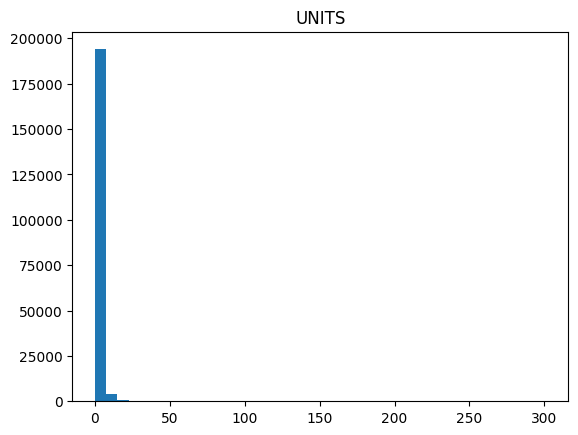

In [3]:
plt.figure()
plt.hist(datos[OBJETIVO], bins=40)
plt.title(OBJETIVO)
plt.show()

## Paso 3: atípicos de la variable objetivo con la regla del IQR

In [4]:
q1 = datos[OBJETIVO].quantile(0.25)
q3 = datos[OBJETIVO].quantile(0.75)
iqr = q3 - q1
fuera = datos[(datos[OBJETIVO] < q1 - 1.5 * iqr) | (datos[OBJETIVO] > q3 + 1.5 * iqr)]
print(f"Atipicos de {OBJETIVO} segun IQR: {len(fuera)}")
fuera.head(10)

Atipicos de UNITS segun IQR: 23716


,DATE_KEY,DATE,D,D_NUM,ITEM_ID,DEPT_ID,CAT_ID,STORE_ID,STATE_ID,UNITS,...,DATE_LY_364,DATE_KEY_LY_364,IS_SNAP,IS_PRE_LAUNCH,IS_STORE_CLOSED,IS_SALES_SPIKE,IS_SUSPECTED_STOCKOUT_CONSERVATIVE,IS_SUSPECTED_STOCKOUT_NB,WEEK_IDX,_LOADED_AT
4,20120915,2012-09-15,d_596,596,HOUSEHOLD_1_409,HOUSEHOLD_1,HOUSEHOLD,TX_3,TX,21,...,2011-09-17,20110917.0,True,False,False,False,False,False,85,2026-10-21 00:47:34.371
9,20121105,2012-11-05,d_647,647,FOODS_3_304,FOODS_3,FOODS,WI_2,WI,6,...,2011-11-07,20111107.0,True,False,False,False,False,False,92,2026-10-21 00:50:23.771
25,20160319,2016-03-19,d_1877,1877,FOODS_3_433,FOODS_3,FOODS,CA_1,CA,3,...,2015-03-21,20150321.0,False,False,False,False,False,False,268,2026-10-21 03:25:55.449
33,20120916,2012-09-16,d_597,597,FOODS_1_169,FOODS_1,FOODS,CA_3,CA,5,...,2011-09-18,20110918.0,False,False,False,False,False,False,85,2026-10-21 00:47:34.371
36,20120916,2012-09-16,d_597,597,FOODS_3_723,FOODS_3,FOODS,CA_3,CA,44,...,2011-09-18,20110918.0,False,False,False,False,False,False,85,2026-10-21 00:47:34.371
37,20120916,2012-09-16,d_597,597,HOBBIES_1_067,HOBBIES_1,HOBBIES,CA_3,CA,3,...,2011-09-18,20110918.0,False,False,False,False,False,False,85,2026-10-21 00:47:34.371
40,20160319,2016-03-19,d_1877,1877,FOODS_2_186,FOODS_2,FOODS,CA_3,CA,3,...,2015-03-21,20150321.0,False,False,False,False,False,False,268,2026-10-21 03:25:55.449
60,20120731,2012-07-31,d_550,550,FOODS_3_462,FOODS_3,FOODS,TX_2,TX,5,...,2011-08-02,20110802.0,False,False,False,False,False,False,78,2026-10-21 00:44:57.421
72,20160319,2016-03-19,d_1877,1877,HOBBIES_1_398,HOBBIES_1,HOBBIES,TX_3,TX,7,...,2015-03-21,20150321.0,False,False,False,False,False,False,268,2026-10-21 03:25:55.449
85,20121106,2012-11-06,d_648,648,FOODS_2_186,FOODS_2,FOODS,WI_2,WI,3,...,2011-11-08,20111108.0,True,False,False,False,False,False,92,2026-10-21 00:50:23.771


## Paso 4: la relación entre el objetivo y la variable que más esperas que influya

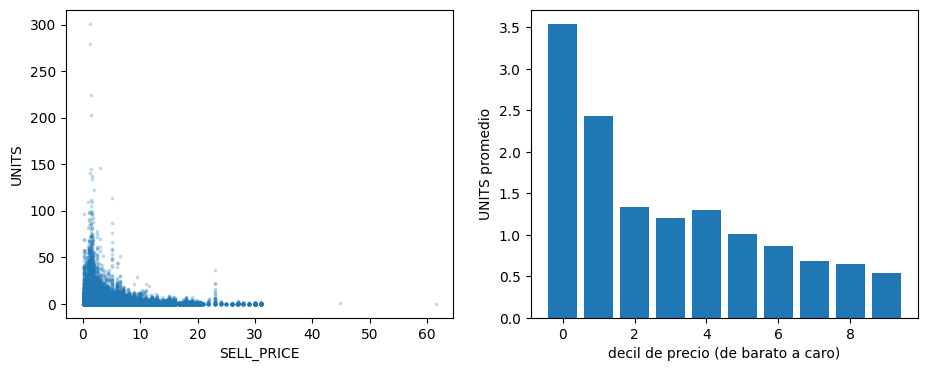

tramo_precio
(0.049, 1.25]    3.54
(1.25, 1.98]     2.43
(1.98, 2.48]     1.33
(2.48, 2.88]     1.20
(2.88, 3.47]     1.30
(3.47, 3.98]     1.01
(3.98, 4.98]     0.86
(4.98, 6.36]     0.69
(6.36, 8.77]     0.65
(8.77, 61.46]    0.54
Name: UNITS, dtype: float64
Correlacion de Spearman precio-unidades: -0.211


In [5]:
# TODO: elige la variable de entrada que esperas que mas influya en el
# objetivo y grafica su relacion con el (dispersion si es numerica,
# promedio del objetivo por grupo si es categorica).

con_precio = datos.dropna(subset=["SELL_PRICE"]).copy()
con_precio["tramo_precio"] = pd.qcut(con_precio["SELL_PRICE"], 10)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].scatter(con_precio["SELL_PRICE"], con_precio[OBJETIVO], s=3, alpha=0.2)
ejes[0].set_xlabel("SELL_PRICE")
ejes[0].set_ylabel(OBJETIVO)
promedio = con_precio.groupby("tramo_precio", observed=True)[OBJETIVO].mean()
ejes[1].bar(range(len(promedio)), promedio.values)
ejes[1].set_xlabel("decil de precio (de barato a caro)")
ejes[1].set_ylabel("UNITS promedio")
plt.show()
print(promedio.round(2))
print("Correlacion de Spearman precio-unidades:",
      round(con_precio[["SELL_PRICE", OBJETIVO]].corr(method="spearman").iloc[0, 1], 3))

## Paso 5: tres hallazgos que afectarían el modelado

Para cada hallazgo: una celda de código con la consulta o el gráfico que lo confirma (un filtro, un `groupby`, una correlación), y debajo una celda de texto con qué encontraste, el número que lo confirma y qué cambia en el modelo por su causa (una fila que quitas, una columna que no puedes usar, una variable que hay que transformar).

### Hallazgo 1

In [6]:
# TODO: la consulta o el grafico que confirma el hallazgo 1.

print("Filas con 0 unidades:", round((datos[OBJETIVO] == 0).mean() * 100, 1), "%")
print("Promedio:", round(datos[OBJETIVO].mean(), 3), "| mediana:", datos[OBJETIVO].median(), "| maximo:", datos[OBJETIVO].max())
print("Filas con mas de 20 unidades:", (datos[OBJETIVO] > 20).sum())
datos[OBJETIVO].value_counts().sort_index().head(8)

Filas con 0 unidades: 68.0 %
Promedio: 1.11 | mediana: 0.0 | maximo: 301
Filas con mas de 20 unidades: 1046


UNITS
0    135873
1     26715
2     13529
3      7272
4      4483
5      2860
6      1950
7      1280
Name: count, dtype: int64

El 68% de las filas tiene 0 unidades, la mediana es 0 y el promedio 1.11, con un máximo de 301. Es un objetivo con muchísimos ceros y una cola larga. Qué cambia en el modelo: una línea base que siempre predice 0 es muy exigente con el error absoluto medio, así que la métrica para comparar modelos tiene que ser el RMSE, que sí castiga fallar en las ventas grandes. Y 1,046 filas con más de 20 unidades pesan mucho en el RMSE; las dejo, porque son ventas reales de productos populares, no errores.

### Hallazgo 2

In [7]:
# TODO: la consulta o el grafico que confirma el hallazgo 2.
sin_precio = datos[datos["SELL_PRICE"].isna()]
print("Filas sin precio:", len(sin_precio), f"({len(sin_precio) / len(datos) * 100:.1f}%)")
print("De esas, marcadas IS_PRE_LAUNCH:", sin_precio["IS_PRE_LAUNCH"].sum())
print("Unidades vendidas en esas filas:", sin_precio[OBJETIVO].sum())
print("Porcentaje de ceros fuera de pre-lanzamiento:",
      round((datos.loc[~datos["IS_PRE_LAUNCH"], OBJETIVO] == 0).mean() * 100, 1), "%")

Filas sin precio: 41600 (20.8%)
De esas, marcadas IS_PRE_LAUNCH: 41600
Unidades vendidas en esas filas: 0
Porcentaje de ceros fuera de pre-lanzamiento: 59.6 %


Hay 41,600 filas sin `SELL_PRICE` (20.8%), y todas son `IS_PRE_LAUNCH`: el producto todavía no se vendía en esa tienda, y por eso vendió 0 unidades en todas. No es un faltante al azar: el precio falta justo porque no hay venta. Qué cambia en el modelo: no puedo imputar el precio y olvidarme, porque se pierde esa información. Imputo el precio con la mediana y dejo `IS_PRE_LAUNCH` como columna para que el modelo sepa por qué falta. Esta columna sí existe al momento de predecir (se sabe si un producto ya salió a la venta), así que se puede usar. Además, esas filas inflan los ceros: fuera de pre-lanzamiento el porcentaje de ceros baja de 68% a 59.6%.

### Hallazgo 3

In [8]:
# TODO: la consulta o el grafico que confirma el hallazgo 3.
print("Revenue = unidades x precio:",
      (datos["REVENUE"].dropna() - (datos["UNITS"] * datos["SELL_PRICE"]).dropna()).abs().max() < 0.01)
for col in ["IS_SALES_SPIKE", "IS_SUSPECTED_STOCKOUT_CONSERVATIVE", "IS_SUSPECTED_STOCKOUT_NB"]:
    print(col, datos.groupby(col)[OBJETIVO].agg(["count", "mean"]).round(2).to_dict("index"))

Revenue = unidades x precio: True
IS_SALES_SPIKE {False: {'count': 199816, 'mean': 1.11}, True: {'count': 17, 'mean': 51.06}}
IS_SUSPECTED_STOCKOUT_CONSERVATIVE {False: {'count': 193236, 'mean': 1.15}, True: {'count': 6597, 'mean': 0.0}}
IS_SUSPECTED_STOCKOUT_NB {False: {'count': 177044, 'mean': 1.25}, True: {'count': 22789, 'mean': 0.0}}


`REVENUE` es exactamente `UNITS` por `SELL_PRICE`: contiene la respuesta. Los dos indicadores de desabastecimiento sospechado se calculan a partir de ventas en cero (cuando valen verdadero, el promedio de `UNITS` es exactamente 0.0), y `IS_SALES_SPIKE` marca las 17 filas con ventas enormes (promedio de 51 unidades). Ninguna de estas columnas existe antes de que el día pase. Qué cambia en el modelo: las cuatro quedan fuera de las columnas de entrada. Si entraran, el modelo parecería muy bueno en la prueba y no serviría para predecir nada nuevo.